# Restaurant Food Waste Prediction with a Stacking Ensemble (Restaurant Dataset)

This notebook applies the method of `canteen_methodology.ipynb` to `datasets/restaurant_dataset.csv`, which records the food waste of catered events (food type, number of guests, event type and other conditions). The rows are separate events with no dates, so the parts of the method that need a time order are left out: the lagged sales, the LSTM and Stacking 2. It compares four models: Random Forest, XGBoost, SVR and a stacking ensemble that combines them through a Ridge regression meta-learner.

Before any modelling, Section 1 checks the data quality: missing values, text formatting, category labels, invalid values, consistency between columns, outliers and duplicate records. Duplicate rows are removed before the split, so no event appears in both the training and the test set.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading, data quality checks and duplicate removal |
| 2 | Data analysis |
| 3 | One-hot encoding, train/test split, scaling |
| 4 | Evaluation metrics |
| 5 | Random Forest, XGBoost and SVR with grid search |
| 6 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 7 | Results and plots |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. On Google Colab the GitHub repository is cloned first;
# when run locally, the notebook already sits next to the dataset in the repository folder.
import os, sys
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/restaurant_dataset.csv"

if "google.colab" in sys.modules and not os.path.exists(DATA_PATH):
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings
import time, random, warnings
warnings.filterwarnings("ignore")

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the train/test split and the tree models
TEST_SIZE         = 0.20      # share of rows held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to the original units
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # candidate regularisation strengths for the Ridge meta-learner
TARGET            = "Wastage Food Amount"               # column being forecast
UNIT              = "amount"                            # the dataset gives no unit for the waste amount

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python and NumPy random generators so results are repeatable
    random.seed(seed); np.random.seed(seed)
set_seeds()

## 1. Data loading and data quality
This loads the dataset, checks its quality and removes duplicate rows before any modelling.

In [3]:
df = pd.read_csv(DATA_PATH)       # each row is a separate event; the rows have no dates, so the file order is kept
print("Rows:", len(df), "| Columns:", df.shape[1])
display(df.head())

Rows: 1782 | Columns: 11


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


### Data quality checks and preprocessing
The checks cover missing values, text formatting, category labels, invalid values, consistency between columns, outliers (1.5 x IQR rule), duplicate rows and how varied the values are. Findings and how they are handled:
- No missing values, padded text, inconsistent labels or invalid values, and the waste is never larger than the food prepared.
- The IQR rule flags some large events (many guests) and some high waste values. They stay within realistic ranges, so they are kept.
- Some rows are exact copies of other rows. With a random split, a copy can end up in the training set and another in the test set, so the model would be tested on events it has already seen. Duplicate rows are therefore removed before the split. This step does not use any values from the data, so it can be done before the split.
- Some events have identical inputs but different waste. These are kept as normal variation between events.
- The guest numbers and food quantities only take a few distinct value pairs, so most events share their pair with many others. This suggests the dataset was built from a small number of base records; it cannot be changed and is noted as a limitation.

In [4]:
CAT_RAW = df.select_dtypes(exclude="number").columns.tolist()
NUM_RAW = ["Number of Guests", "Quantity of Food", TARGET]

# Missing values, blank or padded text and category labels
print("Missing values (expect 0):", df.isna().sum().sum(),
      "| Text with leading or trailing spaces (expect 0):", int(sum((df[c] != df[c].str.strip()).sum() for c in CAT_RAW)))
for c in CAT_RAW:
    print(f"  {c}: {df[c].value_counts().to_dict()}")

# Invalid values and consistency between columns
print("Zero or negative guests, food or waste (expect 0):", int((df[NUM_RAW] <= 0).sum().sum()),
      "| Waste larger than the food prepared (expect 0):", (df[TARGET] > df["Quantity of Food"]).sum())
print(f"Waste as a share of the food prepared: {(df[TARGET] / df['Quantity of Food']).min():.1%} to {(df[TARGET] / df['Quantity of Food']).max():.1%}")

# Outliers by the 1.5 x IQR rule
q1, q3 = df[NUM_RAW].quantile(0.25), df[NUM_RAW].quantile(0.75)
print("Outliers (1.5 x IQR):", ((df[NUM_RAW] < q1 - 1.5 * (q3 - q1)) | (df[NUM_RAW] > q3 + 1.5 * (q3 - q1))).sum().to_dict(),
      "| ranges:", {c: (int(df[c].min()), int(df[c].max())) for c in NUM_RAW})

# Duplicates and repeated values
inputs = [c for c in df.columns if c != TARGET]
print("Duplicate rows:", df.duplicated().sum(), "| groups of identical rows:", df[df.duplicated(keep=False)].groupby(list(df.columns)).ngroups,
      "| most copies of one row:", df[df.duplicated(keep=False)].groupby(list(df.columns)).size().max())
print("Identical inputs with different waste:", int((df.groupby(inputs)[TARGET].nunique() > 1).sum()), "groups")
print("Distinct (guests, food quantity) pairs:", df[["Number of Guests", "Quantity of Food"]].drop_duplicates().shape[0],
      "| distinct waste values:", df[TARGET].nunique())

# Preprocessing: remove duplicate rows, so no event appears in both the training and the test set
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_before - len(df)} | rows left: {len(df)}")

Missing values (expect 0): 0 | Text with leading or trailing spaces (expect 0): 0
  Type of Food: {'Meat': 437, 'Baked Goods': 419, 'Dairy Products': 387, 'Fruits': 328, 'Vegetables': 211}
  Event Type: {'Corporate': 515, 'Social Gathering': 461, 'Wedding': 438, 'Birthday': 368}
  Storage Conditions: {'Room Temperature': 1157, 'Refrigerated': 625}
  Purchase History: {'Regular': 1576, 'Occasional': 206}
  Seasonality: {'Winter': 632, 'All Seasons': 623, 'Summer': 527}
  Preparation Method: {'Sit-down Dinner': 781, 'Finger Food': 702, 'Buffet': 299}
  Geographical Location: {'Suburban': 821, 'Urban': 564, 'Rural': 397}
  Pricing: {'High': 674, 'Moderate': 673, 'Low': 435}
Zero or negative guests, food or waste (expect 0): 0 | Waste larger than the food prepared (expect 0): 0
Waste as a share of the food prepared: 2.1% to 15.4%
Outliers (1.5 x IQR): {'Number of Guests': 35, 'Quantity of Food': 0, 'Wastage Food Amount': 10} | ranges: {'Number of Guests': (207, 491), 'Quantity of Food': (2

## 2. Data analysis
This plots how waste varies with the main inputs.

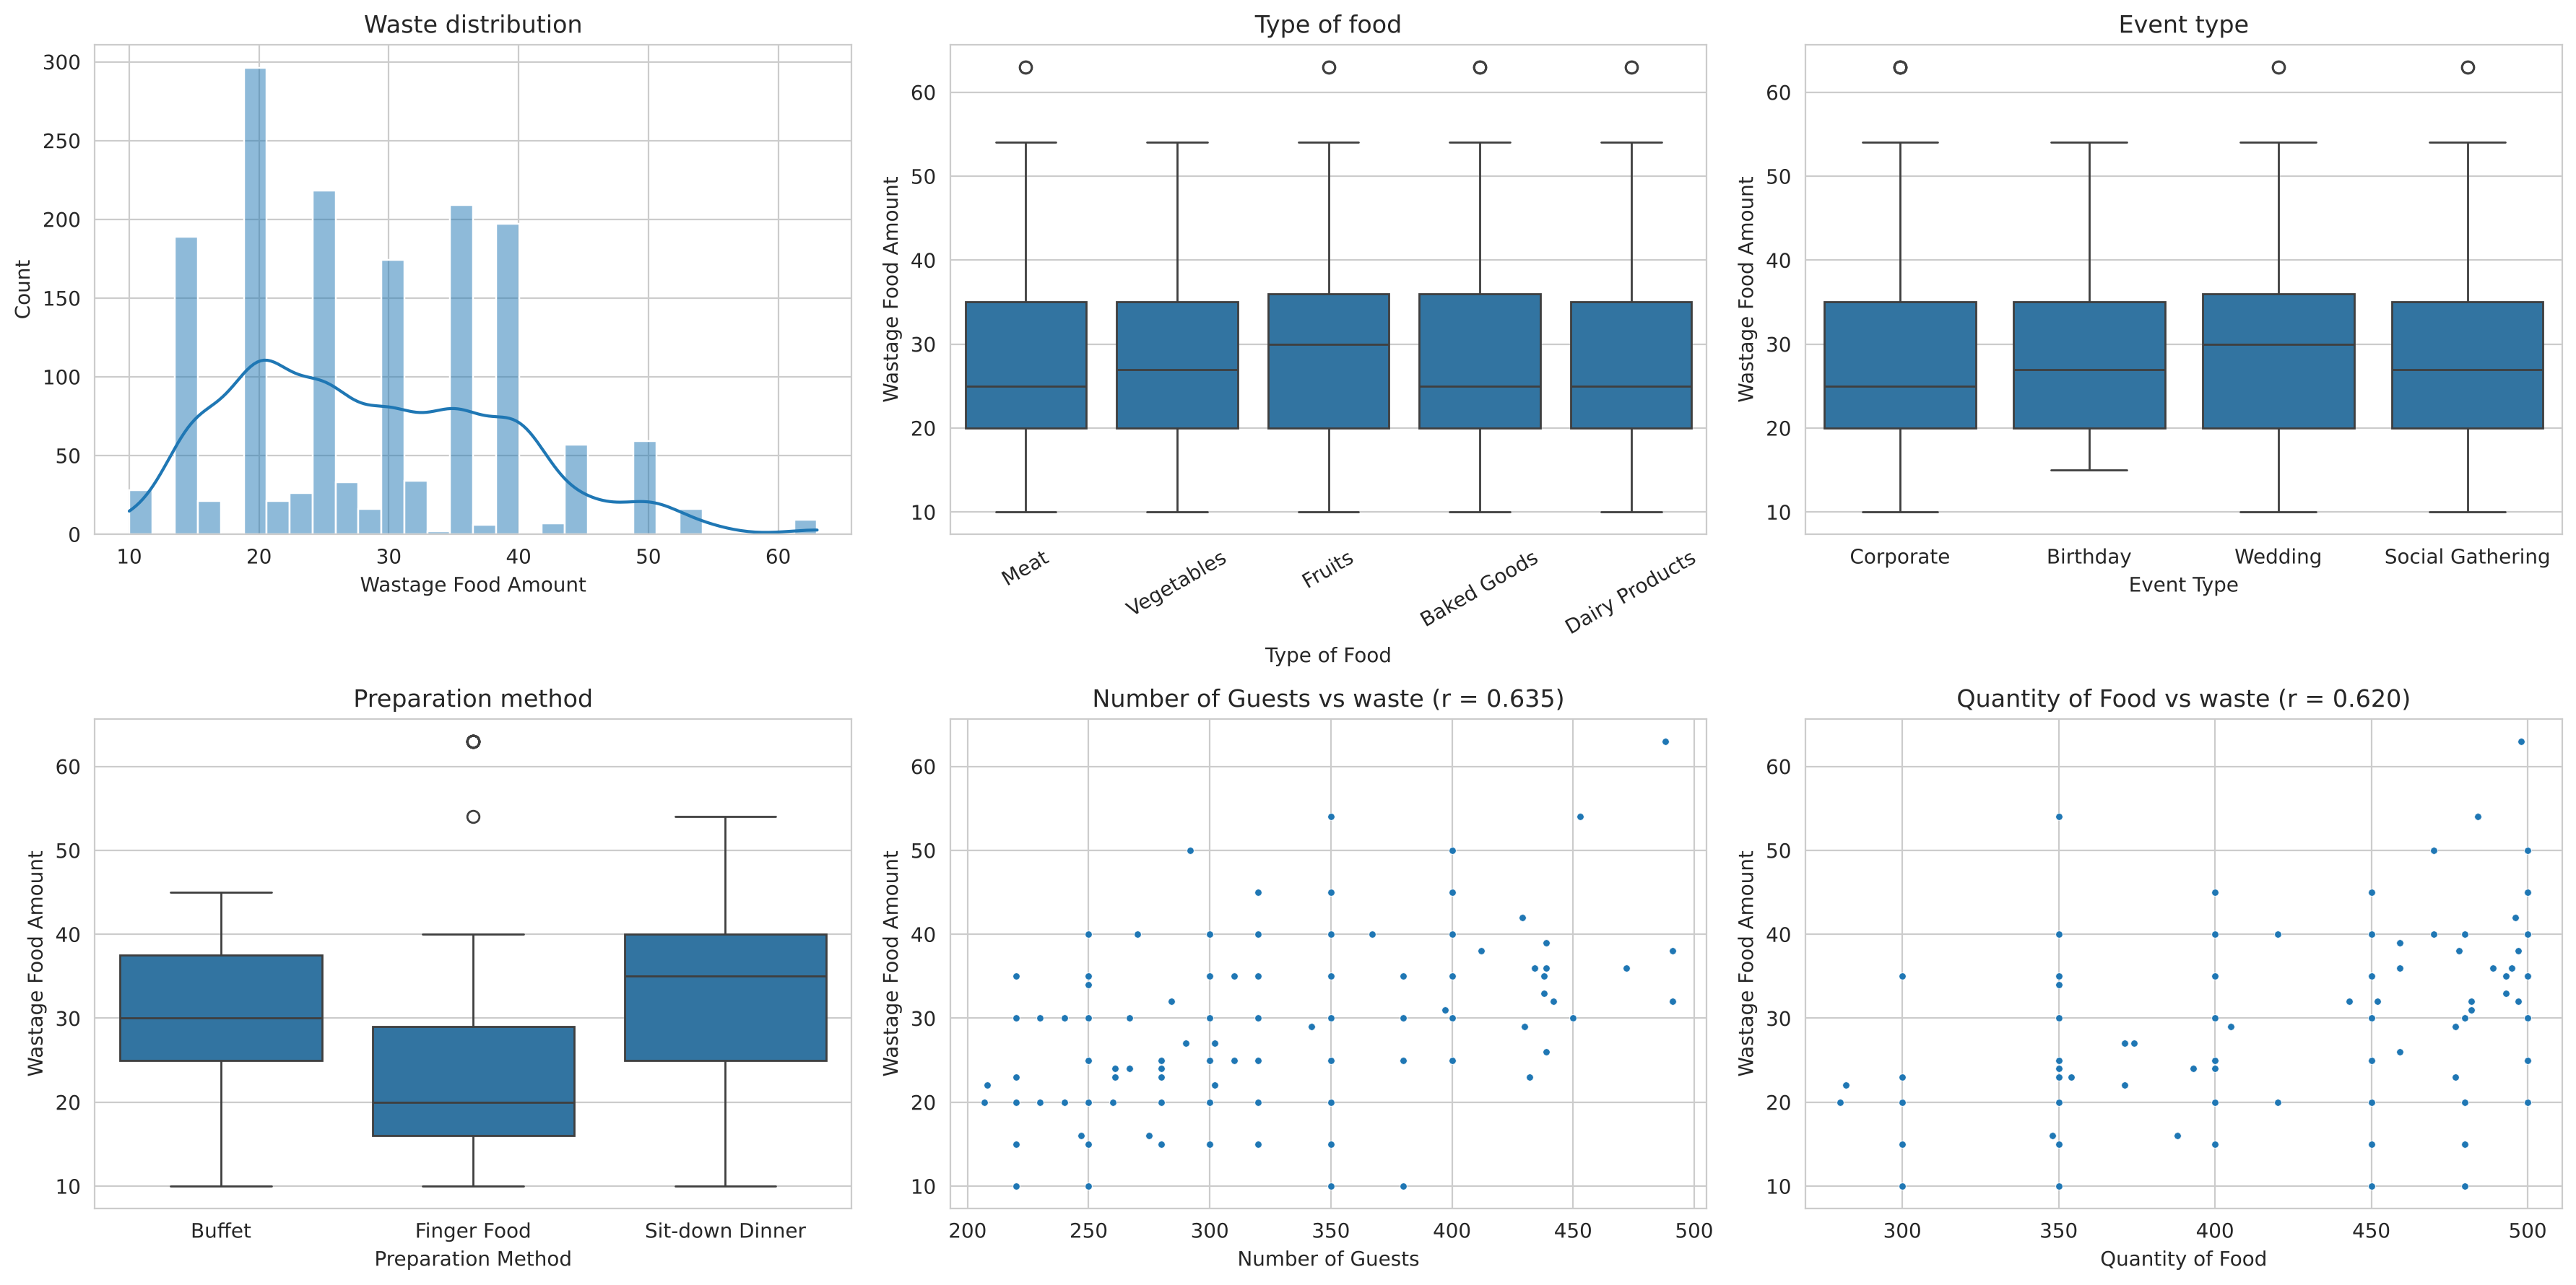

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of waste per event
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Waste distribution")
# Waste by food type, event type and preparation method
sns.boxplot(data=df, x="Type of Food", y=TARGET, ax=ax[0, 1]).set_title("Type of food")
ax[0, 1].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="Event Type", y=TARGET, ax=ax[0, 2]).set_title("Event type")
sns.boxplot(data=df, x="Preparation Method", y=TARGET, ax=ax[1, 0]).set_title("Preparation method")
# Guests and quantity of food against waste, with their correlations in the titles
for a, col in [(ax[1, 1], "Number of Guests"), (ax[1, 2], "Quantity of Food")]:
    sns.scatterplot(data=df, x=col, y=TARGET, s=12, ax=a).set_title(f"{col} vs waste (r = {df[[col, TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

## 3. Encoding, split and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split at random into 80 % training and 20 % testing.
3. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in its original units.

In [6]:
CAT_COLS = ["Type of Food", "Event Type", "Storage Conditions", "Purchase History", "Seasonality",
            "Preparation Method", "Geographical Location", "Pricing"]
NUM_COLS = ["Number of Guests", "Quantity of Food"]

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# Random 80/20 split on row positions
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

27 inputs | train (1294, 27) | test (324, 27)
['Number of Guests', 'Quantity of Food', 'Type of Food_Baked Goods', 'Type of Food_Dairy Products', 'Type of Food_Fruits', 'Type of Food_Meat', 'Type of Food_Vegetables', 'Event Type_Birthday', 'Event Type_Corporate', 'Event Type_Social Gathering', 'Event Type_Wedding', 'Storage Conditions_Refrigerated', 'Storage Conditions_Room Temperature', 'Purchase History_Occasional', 'Purchase History_Regular', 'Seasonality_All Seasons', 'Seasonality_Summer', 'Seasonality_Winter', 'Preparation Method_Buffet', 'Preparation Method_Finger Food', 'Preparation Method_Sit-down Dinner', 'Geographical Location_Rural', 'Geographical Location_Suburban', 'Geographical Location_Urban', 'Pricing_High', 'Pricing_Low', 'Pricing_Moderate']


## 4. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 7.

In [7]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in target units / %), R2, training time and test-set size
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MAPE (%)": mape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

## 5. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to the original units.

In [8]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to the original units
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}  (7.7s)


XGBoost  {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 100}  (1.2s)


SVR      {'regressor__C': 1, 'regressor__epsilon': 0.2}  (0.6s)


## 6. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by an outer 5-fold grid search, which rebuilds the whole stack for every candidate value.

In [9]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions
stack = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                          final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
# Outer grid search over Ridge alpha; each candidate rebuilds and scores the whole stack
s1 = GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                  cv=CV_FOLDS, scoring=SCORING).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: {s1.best_params_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 1: {'final_estimator__alpha': 10} | Ridge weights [RF, XGB, SVR] = [ 0.416  0.6   -0.017] (30.3s)


## 7. Results
These are the test-set metrics for all four models, evaluated on the same test rows.

In [10]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,
RF,1.811,7.045,92.955,0.924,7.701,324
XGBoost,1.914,7.484,92.516,0.922,1.198,324
SVR,4.080,16.279,83.721,0.710,0.630,324
"Stacking 1 (RF, XGBoost, SVR)",1.828,7.150,92.850,0.925,30.308,324


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

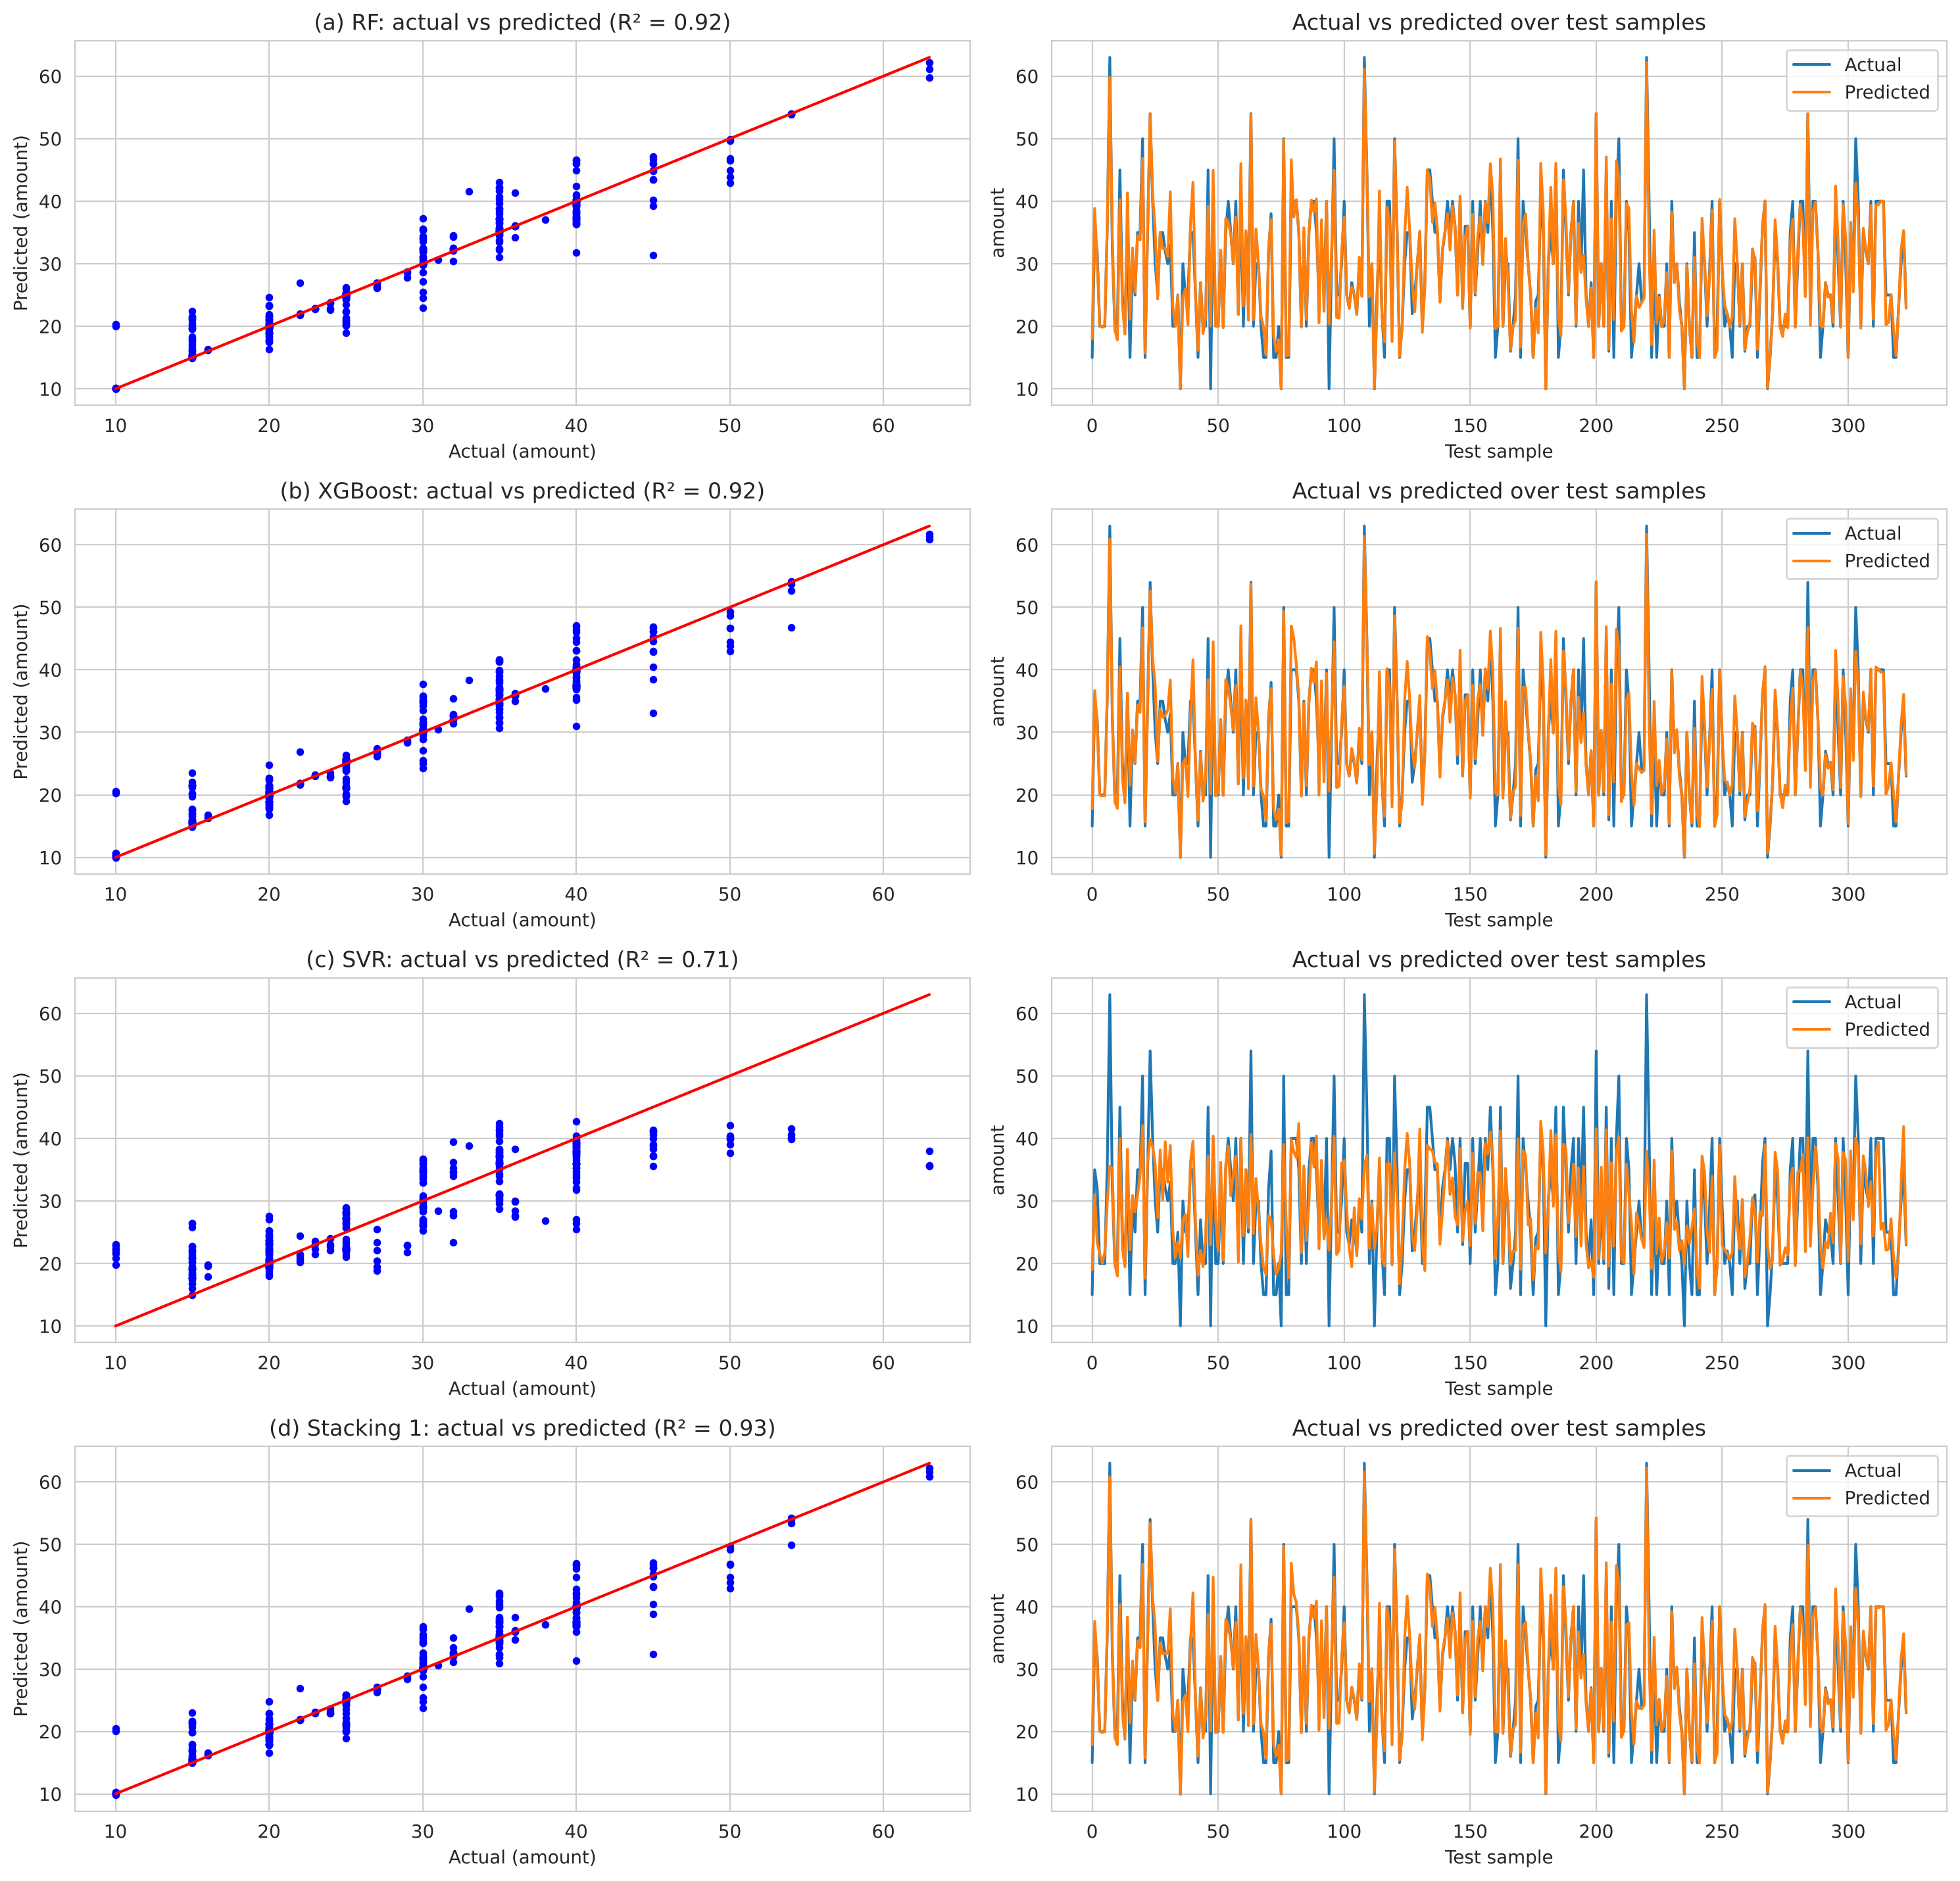

In [11]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdef'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

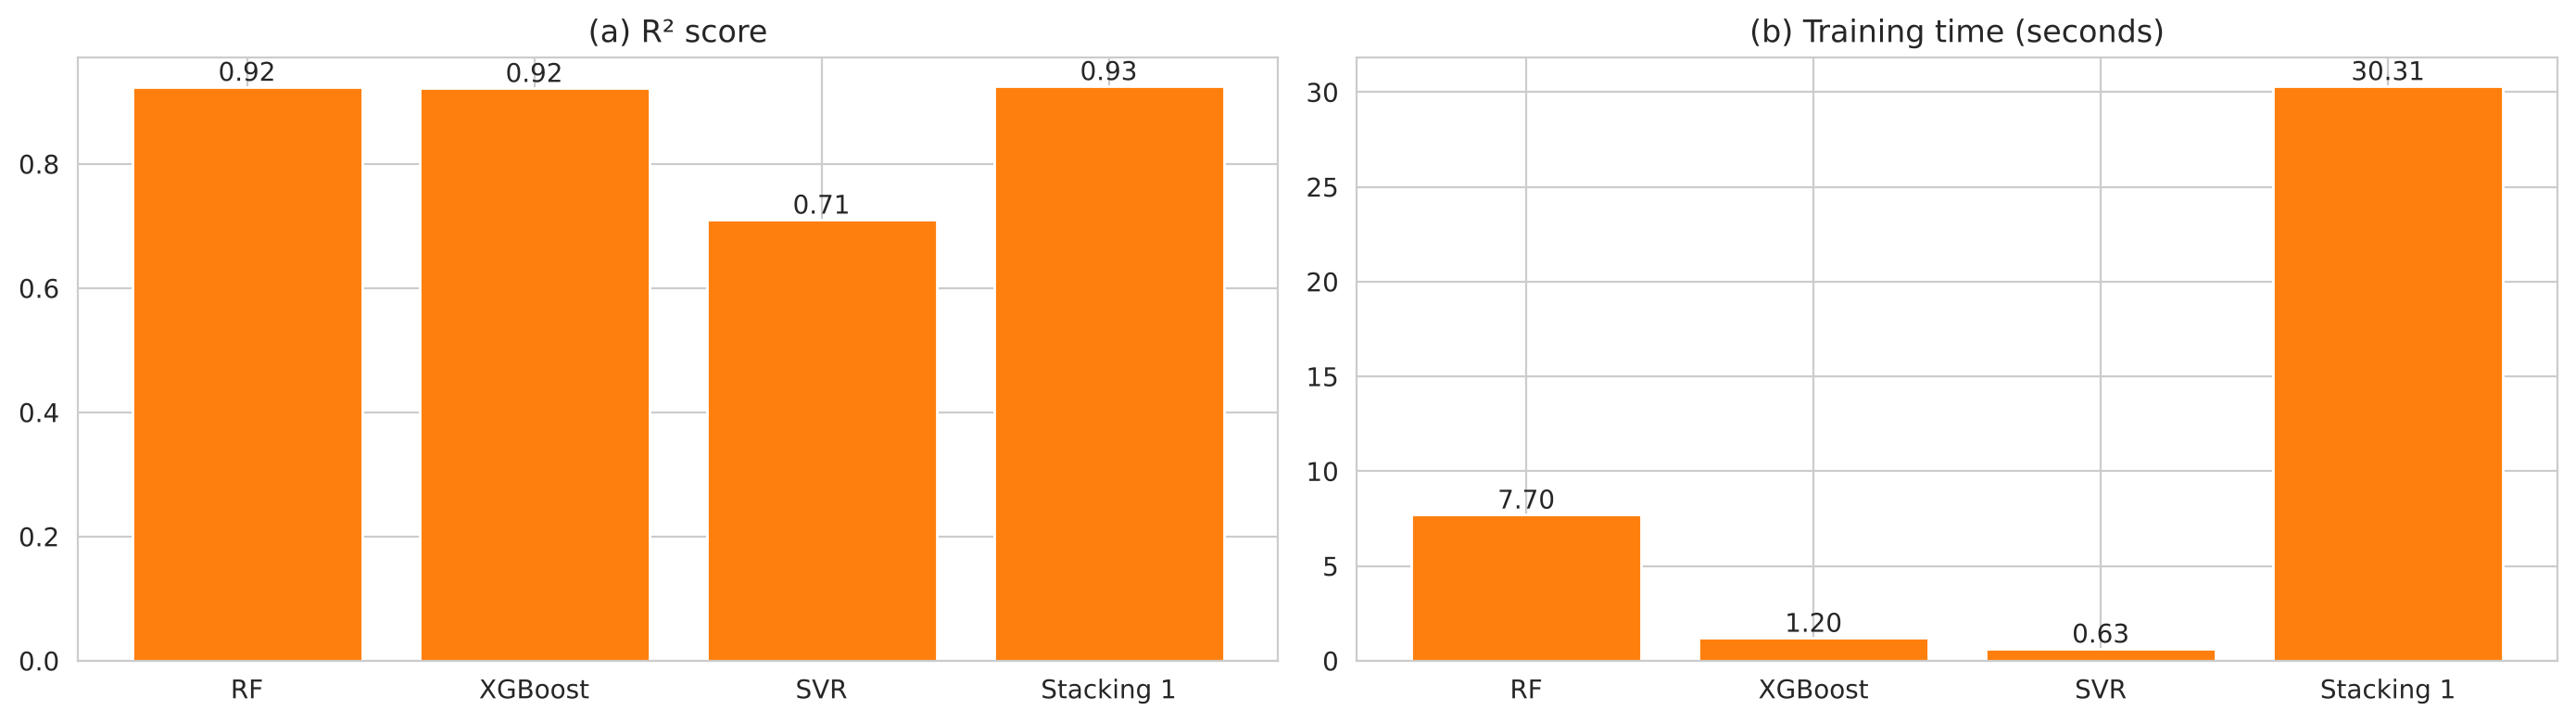

In [12]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()